In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option("display.max_columns", None)

# Better chart appearance
sns.set_style("whitegrid")

# Display plots inside notebook
%matplotlib inline

In [2]:
df = pd.read_csv("../data/processed/telco_customer_churn_cleaned.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7032, 21)

In [5]:
df["Churn"].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

In [6]:
round(df["Churn"].value_counts(normalize=True) * 100, 2)

Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64

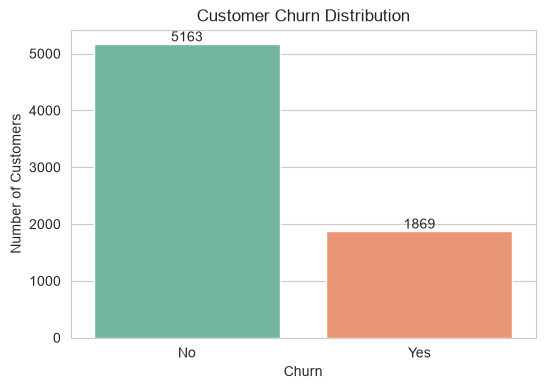

In [7]:
plt.figure(figsize=(6,4))

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.show()

### Business Question

What percentage of customers churn?

### Observation

The dataset contains significantly more customers who stayed than customers who churned.

Approximately one-fourth of the customers left the company, while the majority remained.

### Business Insight

The company retains most of its customers, but the churn rate is still substantial enough to impact revenue and customer acquisition costs. Predicting customers who are likely to churn can help the business take proactive retention measures.


In [8]:
df["gender"].value_counts()

gender
Male      3549
Female    3483
Name: count, dtype: int64

In [9]:
round(df["gender"].value_counts(normalize=True) * 100, 2)

gender
Male      50.47
Female    49.53
Name: proportion, dtype: float64

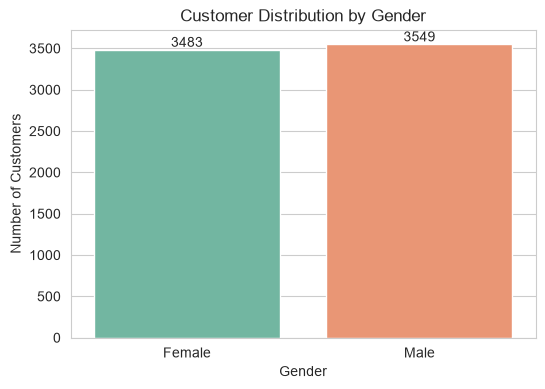

In [10]:
plt.figure(figsize=(6,4))

ax = sns.countplot(
    data=df,
    x="gender",
    hue="gender",
    palette="Set2",
    legend=False
)

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

### Business Question

Is the customer base dominated by a particular gender?

### Observation

The customer base is almost evenly distributed between male and female customers.

### Business Insight

Gender alone is unlikely to explain customer churn because both groups are similarly represented.

In [11]:
df["SeniorCitizen"].value_counts()

SeniorCitizen
0    5890
1    1142
Name: count, dtype: int64

In [12]:
round(df["SeniorCitizen"].value_counts(normalize=True) * 100, 2)

SeniorCitizen
0    83.76
1    16.24
Name: proportion, dtype: float64

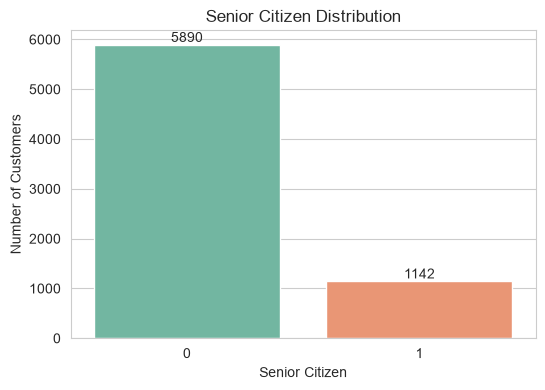

In [13]:
plt.figure(figsize=(6,4))

ax = sns.countplot(
    data=df,
    x="SeniorCitizen",
    hue="SeniorCitizen",
    palette="Set2",
    legend=False
)

plt.title("Senior Citizen Distribution")
plt.xlabel("Senior Citizen")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

### Business Question

How many customers are senior citizens?

### Observation

Most customers are not senior citizens.

### Business Insight

The dataset is dominated by non-senior customers, so age-related customer behavior should be interpreted carefully.

In [14]:
df["Partner"].value_counts()

Partner
No     3639
Yes    3393
Name: count, dtype: int64

In [15]:
round(df["Partner"].value_counts(normalize=True) * 100, 2)

Partner
No     51.75
Yes    48.25
Name: proportion, dtype: float64

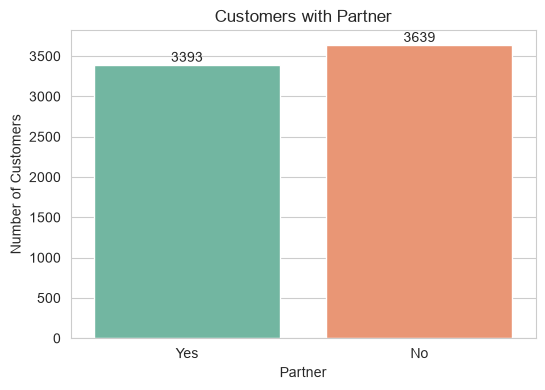

In [16]:
plt.figure(figsize=(6,4))

ax = sns.countplot(
    data=df,
    x="Partner",
    hue="Partner",
    palette="Set2",
    legend=False
)

plt.title("Customers with Partner")
plt.xlabel("Partner")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

### Business Question

Do most customers have a partner?

### Observation

The customer base contains both customers with and without partners in comparable proportions.

### Business Insight

Relationship status may influence customer behavior, but additional analysis with the churn variable is required.

In [17]:
df["Dependents"].value_counts()

Dependents
No     4933
Yes    2099
Name: count, dtype: int64

In [18]:
round(df["Dependents"].value_counts(normalize=True) * 100, 2)

Dependents
No     70.15
Yes    29.85
Name: proportion, dtype: float64

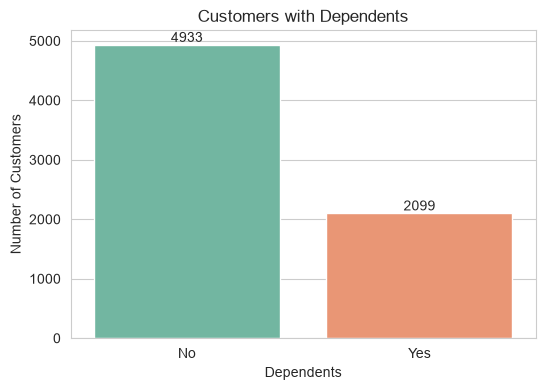

In [19]:
plt.figure(figsize=(6,4))

ax = sns.countplot(
    data=df,
    x="Dependents",
    hue="Dependents",
    palette="Set2",
    legend=False
)

plt.title("Customers with Dependents")
plt.xlabel("Dependents")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

### Business Question

How many customers have dependents?

### Observation

A larger proportion of customers do not have dependents.

### Business Insight

This variable may become more meaningful when analyzed against churn in the bivariate analysis phase.

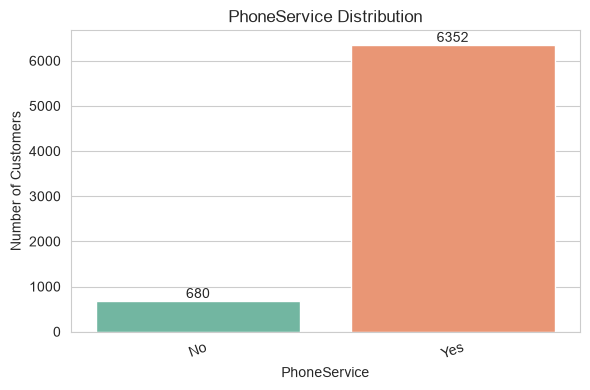

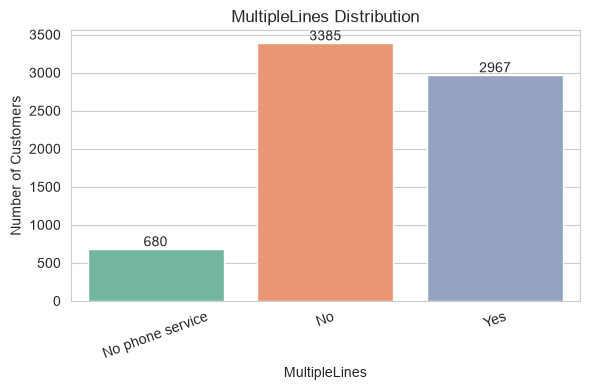

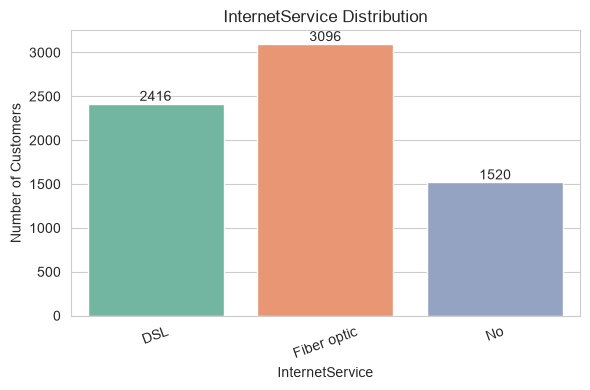

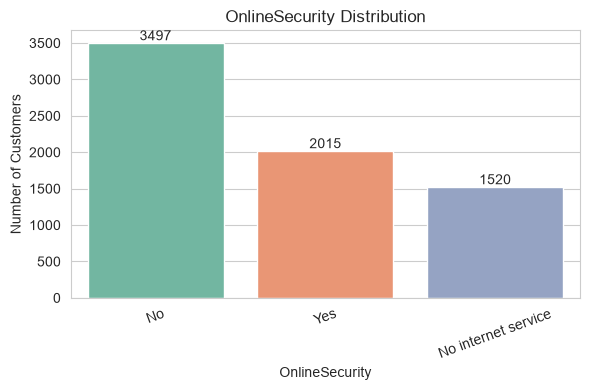

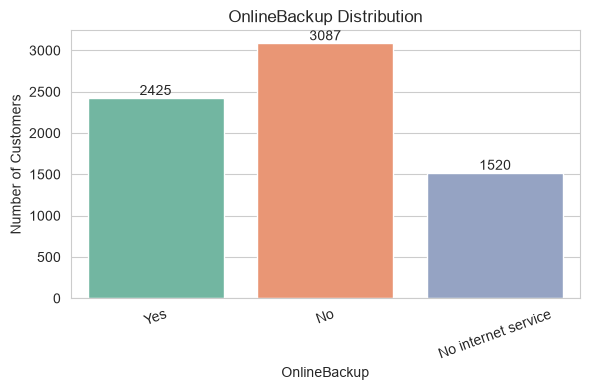

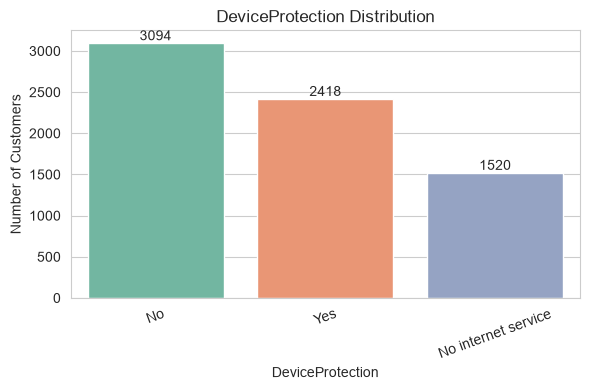

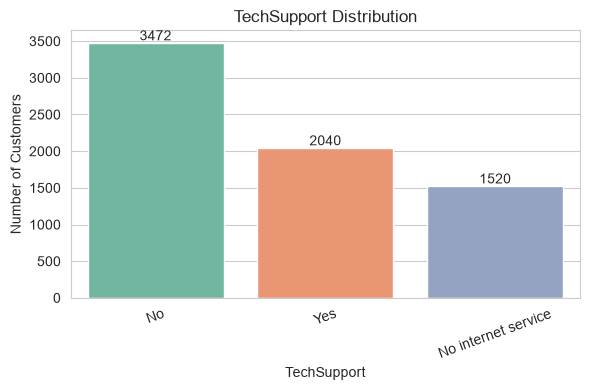

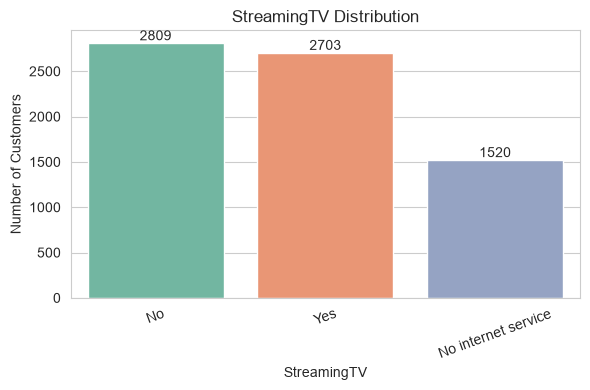

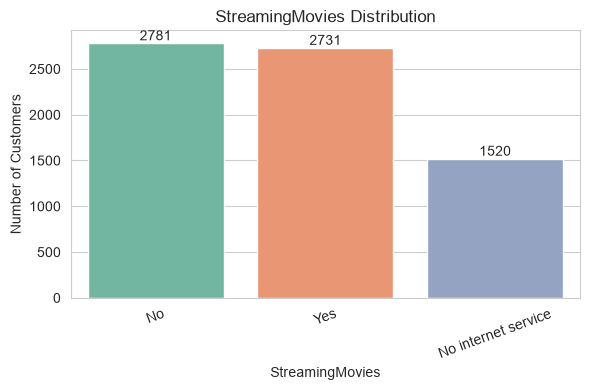

In [20]:
service_columns = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

for column in service_columns:

    plt.figure(figsize=(6,4))

    ax = sns.countplot(
        data=df,
        x=column,
        hue=column,
        palette="Set2",
        legend=False
    )

    plt.title(f"{column} Distribution")
    plt.xlabel(column)
    plt.ylabel("Number of Customers")

    for container in ax.containers:
        ax.bar_label(container)

    plt.xticks(rotation=20)

    plt.tight_layout()
    plt.show()

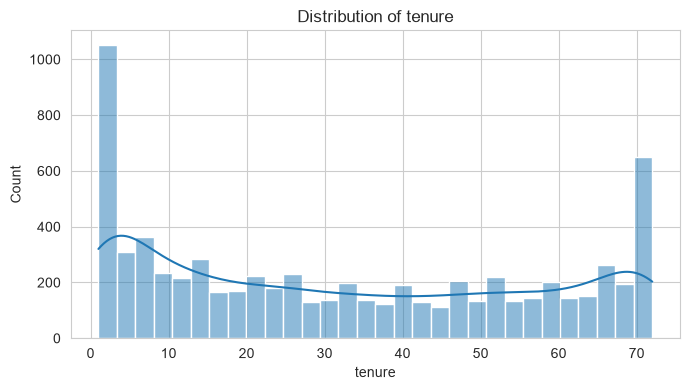

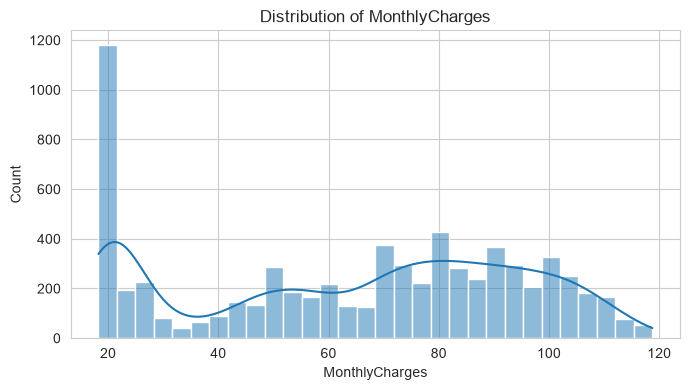

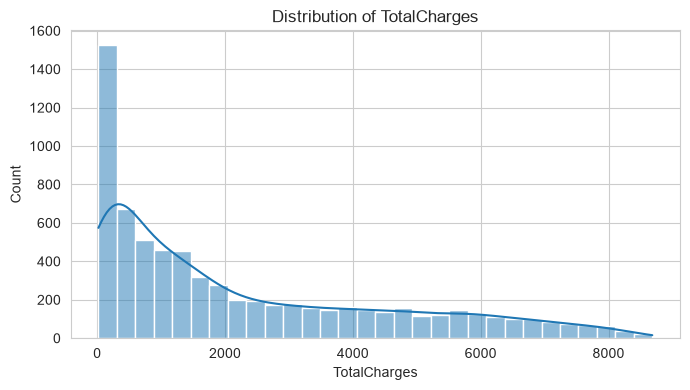

In [21]:
numerical_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for column in numerical_columns:

    plt.figure(figsize=(7,4))

    sns.histplot(
        data=df,
        x=column,
        bins=30,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Count")

    plt.tight_layout()
    plt.show()

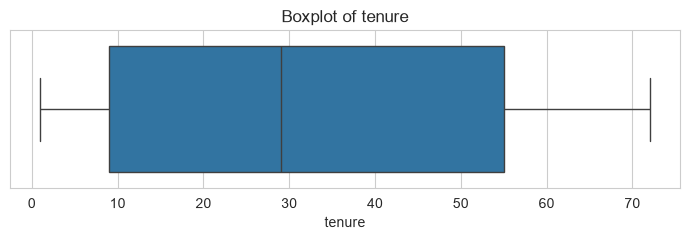

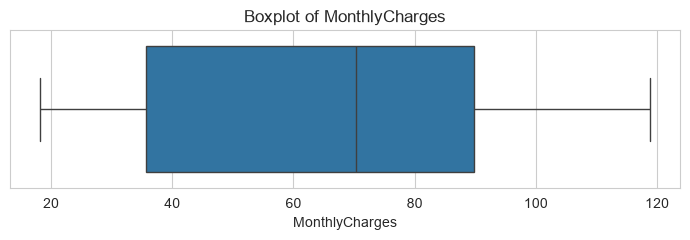

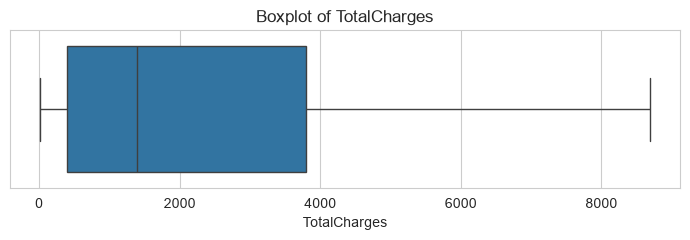

In [22]:
for column in numerical_columns:

    plt.figure(figsize=(7,2.5))

    sns.boxplot(
        data=df,
        x=column
    )

    plt.title(f"Boxplot of {column}")

    plt.tight_layout()
    plt.show()

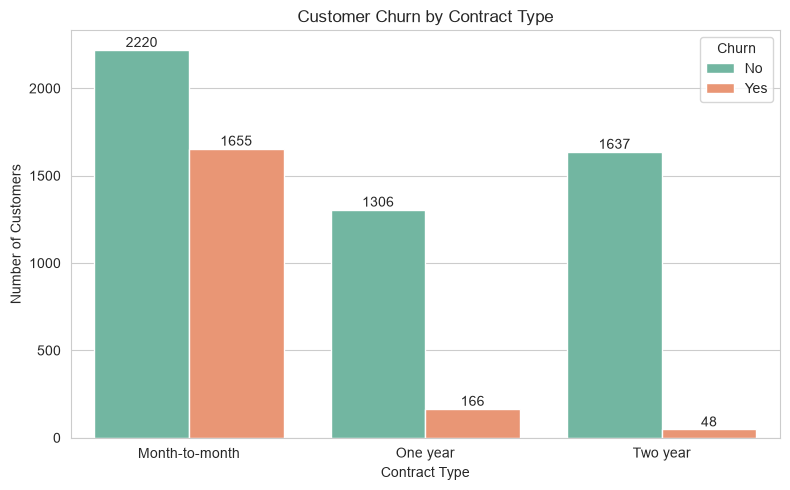

In [23]:
plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=df,
    x="Contract",
    hue="Churn",
    palette="Set2"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [24]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.72,11.28
Two year,97.15,2.85


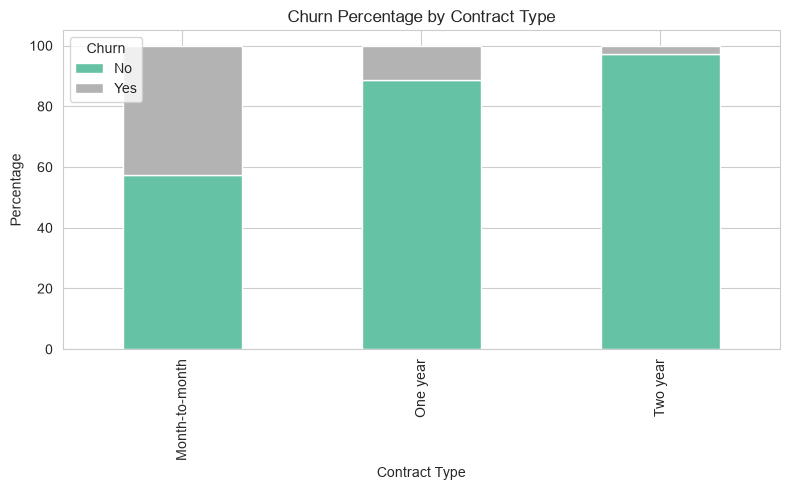

In [25]:
contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5),
    colormap="Set2"
)

plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage")

plt.legend(title="Churn")
plt.tight_layout()

plt.show()

### Business Question

Does contract type influence churn?

### Observation

Customers with month-to-month contracts have a much higher churn rate than customers with one-year or two-year contracts.

Customers with two-year contracts rarely churn.

### Business Insight

Long-term contracts appear to improve customer retention. Customers on month-to-month plans are more likely to leave because they can switch providers easily without contractual commitments.

In [26]:
def plot_churn_percentage(data, feature):

    churn_table = pd.crosstab(
        data[feature],
        data["Churn"],
        normalize="index"
    ) * 100

    display(churn_table.round(2))

    churn_table.plot(
        kind="bar",
        stacked=True,
        figsize=(8,5),
        colormap="Set2"
    )

    plt.title(f"Churn Percentage by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Percentage of Customers")
    plt.legend(title="Churn")

    plt.tight_layout()
    plt.show()

Churn,No,Yes
InternetService,,
DSL,81.00,19.00
Fiber optic,58.11,41.89
No,92.57,7.43


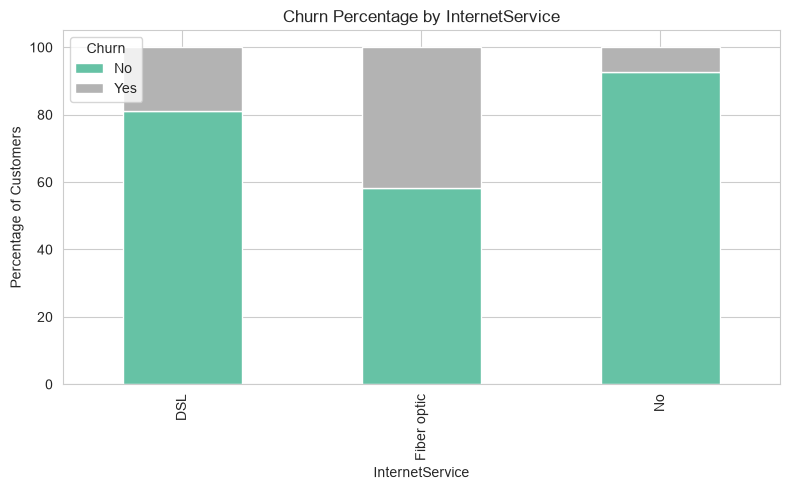

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.27,16.73
Credit card (automatic),84.75,15.25
Electronic check,54.71,45.29
Mailed check,80.80,19.20


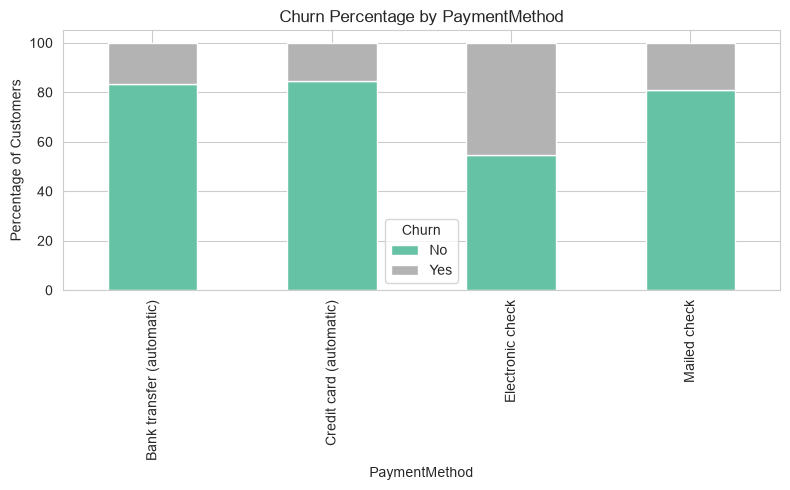

Churn,No,Yes
TechSupport,,
No,58.35,41.65
No internet service,92.57,7.43
Yes,84.80,15.20


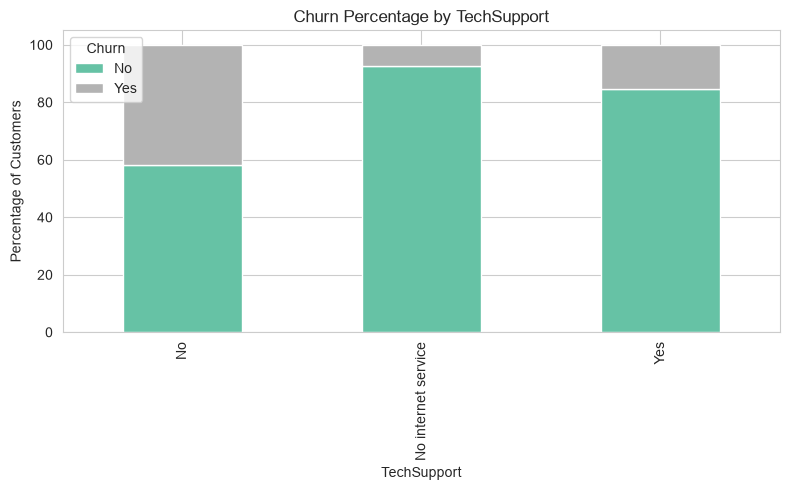

Churn,No,Yes
OnlineSecurity,,
No,58.22,41.78
No internet service,92.57,7.43
Yes,85.36,14.64


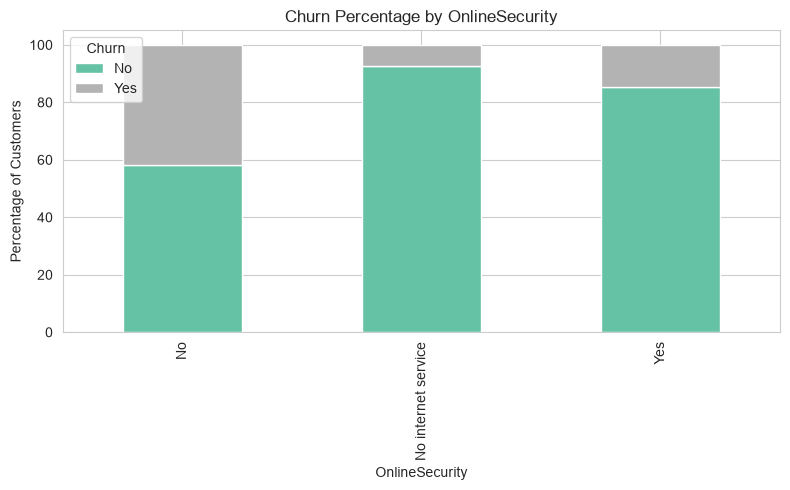

Churn,No,Yes
OnlineBackup,,
No,60.06,39.94
No internet service,92.57,7.43
Yes,78.43,21.57


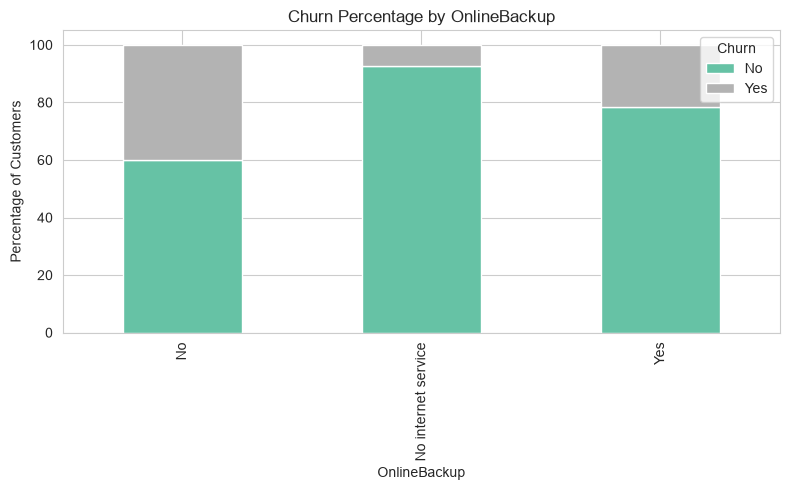

Churn,No,Yes
DeviceProtection,,
No,60.86,39.14
No internet service,92.57,7.43
Yes,77.46,22.54


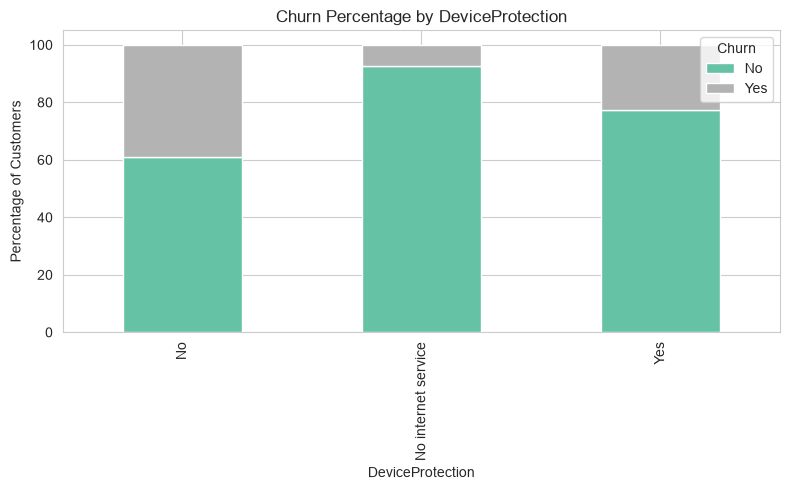

Churn,No,Yes
StreamingTV,,
No,66.46,33.54
No internet service,92.57,7.43
Yes,69.89,30.11


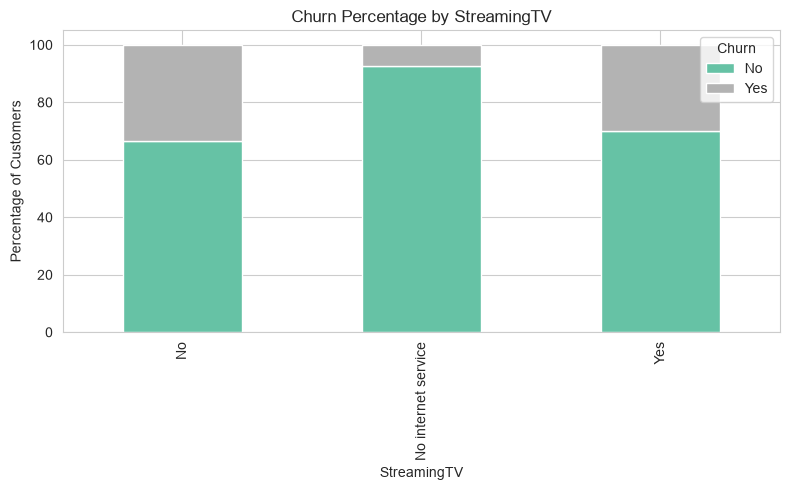

Churn,No,Yes
StreamingMovies,,
No,66.27,33.73
No internet service,92.57,7.43
Yes,70.05,29.95


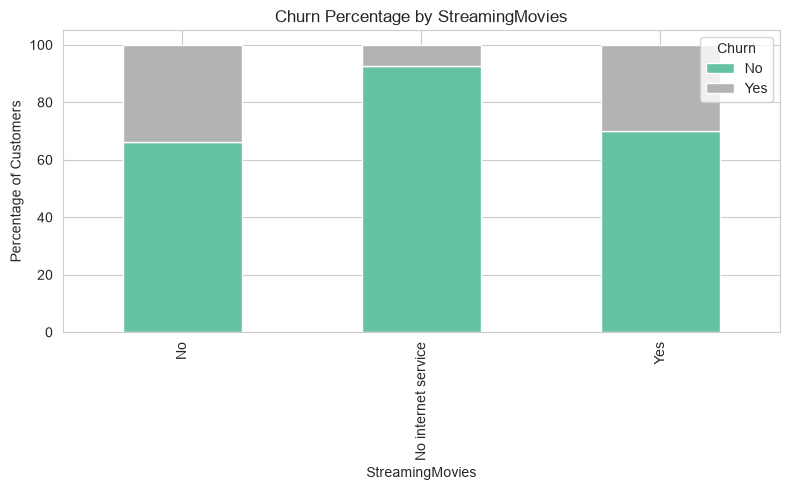

Churn,No,Yes
Partner,,
No,67.02,32.98
Yes,80.28,19.72


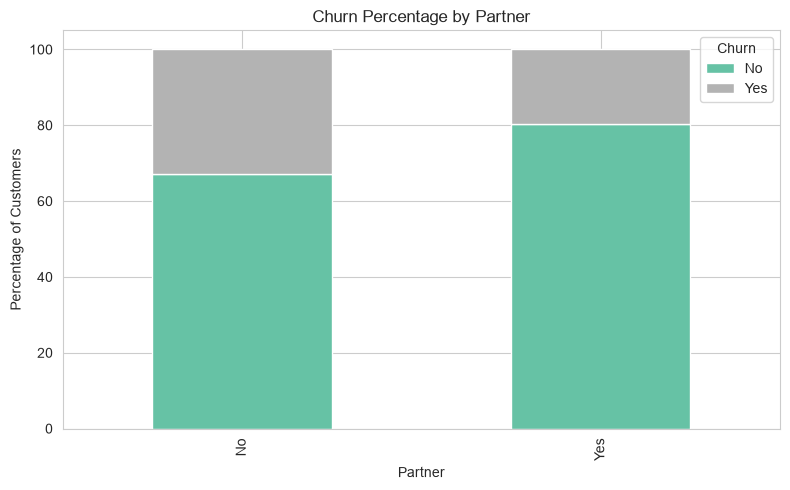

Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.47,15.53


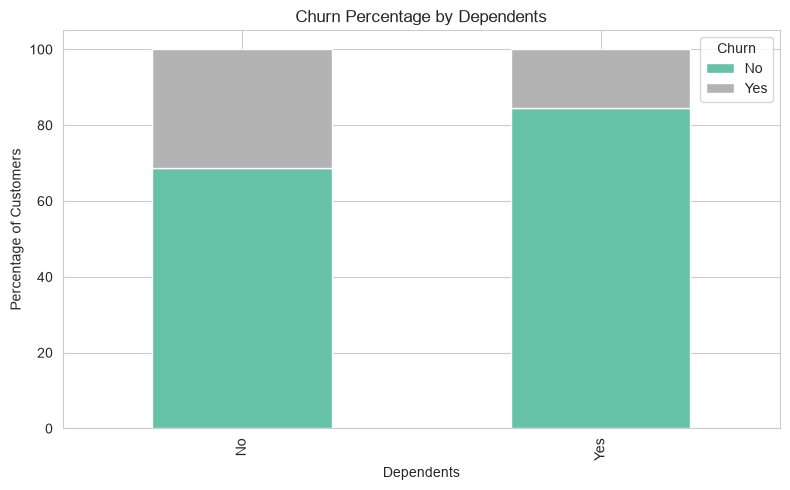

Churn,No,Yes
SeniorCitizen,,
0,76.35,23.65
1,58.32,41.68


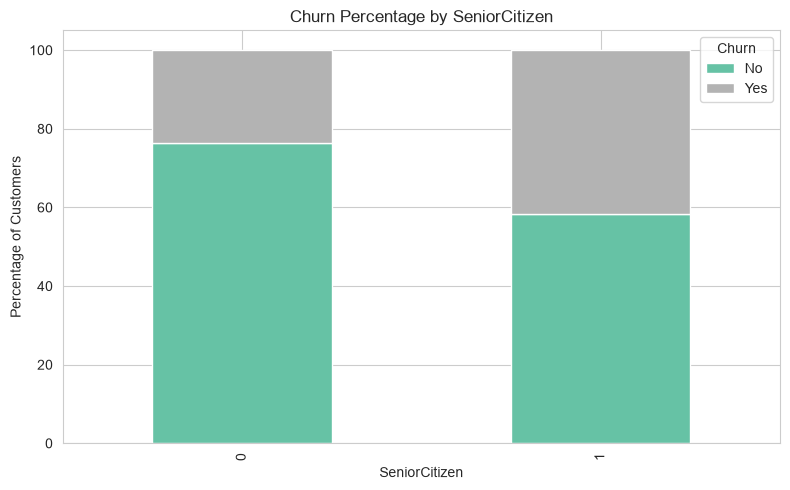

In [27]:
categorical_features = [
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies",
    "Partner",
    "Dependents",
    "SeniorCitizen"
]

for feature in categorical_features:
    plot_churn_percentage(df, feature)

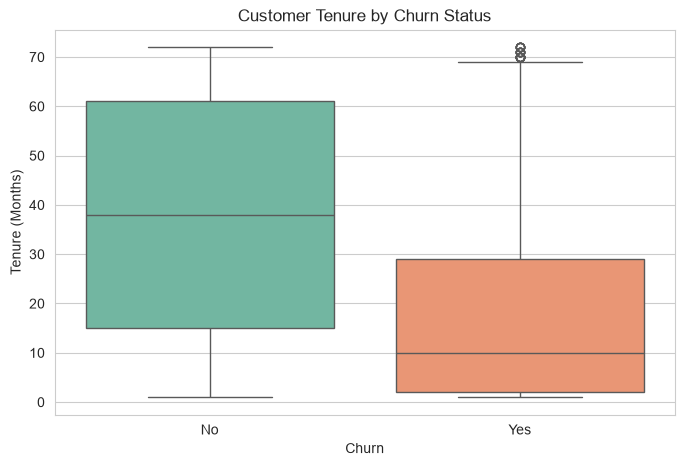

In [28]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

### Business Question

Does customer tenure affect churn?

### Observation

Customers who churn generally have a much lower tenure compared to customers who stay.

### Business Insight

Newer customers are more likely to leave the company. This suggests that customer retention efforts should focus on the early months of the customer lifecycle.

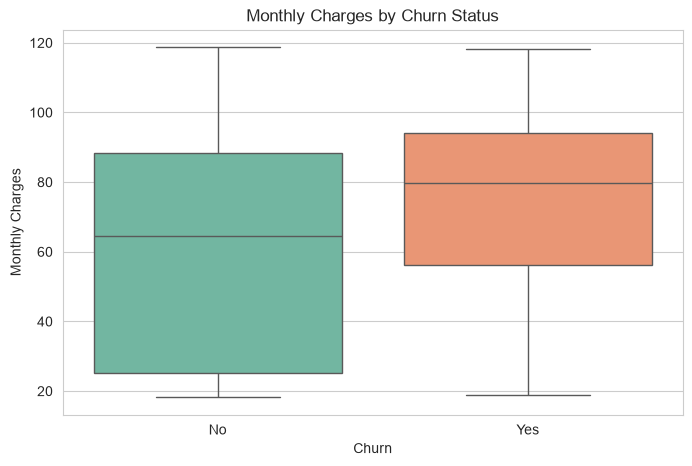

In [29]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

### Observation

Customers who churn tend to have higher monthly charges.

### Business Insight

Higher monthly charges may increase the likelihood of customers leaving, possibly due to cost sensitivity or better offers from competitors.

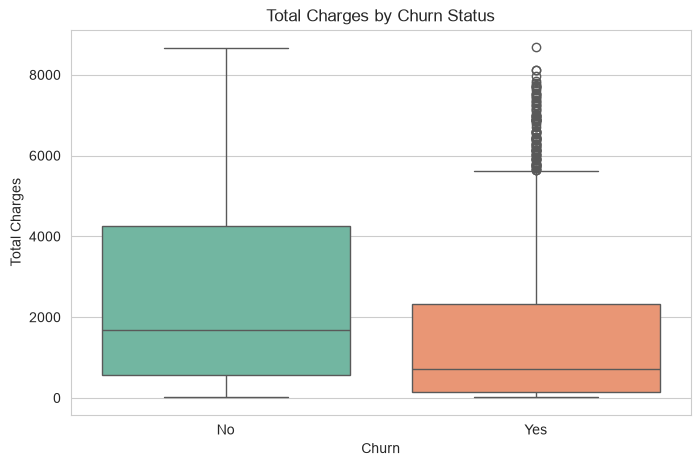

In [30]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Total Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.show()

### Observation

Customers who stay generally have higher total charges.

### Business Insight

Higher total charges usually reflect longer customer relationships. Customers who remain with the company naturally accumulate larger total spending over time.

In [31]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

correlation = df[numerical_features].corr()

correlation

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.246862,0.825880
MonthlyCharges,0.246862,1.000000,0.651065
TotalCharges,0.825880,0.651065,1.000000


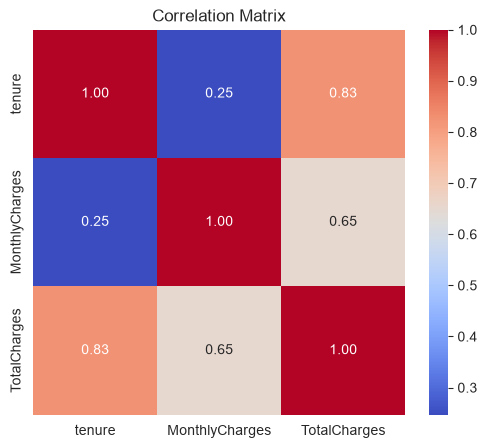

In [32]:
plt.figure(figsize=(6,5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

# Exploratory Data Analysis Summary

## Dataset Overview
- Total Records: 7,032
- Features: 21
- Target Variable: Churn

---

## Key Findings

### Customer Churn
- Approximately one-fourth of customers have churned.
- The dataset shows a moderate class imbalance.

### Customer Demographics
- Male and female customers are almost equally distributed.
- Most customers are not senior citizens.
- A larger proportion of customers do not have dependents.

### Service Usage
- Fiber optic internet is widely used.
- Many customers do not subscribe to Online Security or Tech Support.
- Phone Service adoption is high.

### Contract & Billing
- Month-to-month customers have the highest churn rate.
- Two-year contract customers have the lowest churn rate.
- Customers using Electronic Check tend to churn more frequently.

### Numerical Features
- Customers with shorter tenure are more likely to churn.
- Customers with higher monthly charges tend to churn more.
- Customers who stay longer accumulate higher Total Charges.

---

## Business Recommendations

- Encourage customers to move from month-to-month contracts to long-term contracts.
- Improve onboarding and engagement for new customers.
- Promote Online Security and Tech Support services.
- Review pricing strategies for customers with high monthly charges.
- Identify high-risk customers early and launch targeted retention campaigns.